# Titanic outlier analysis with ArbitraryOutlierCapper

`ArbitraryOutlierCapper` caps numeric values at limits chosen by the analyst. It is different from `Winsorizer`: the transformer does not estimate limits from the sample. The limits must come from domain knowledge, measurement rules, or a documented policy.

This notebook uses Titanic passenger data and demonstrates explicit limits for age, fare, siblings/spouses, and parents/children aboard. The values are teaching examples and should be revised for a real analysis.

## Why use arbitrary limits?

A domain boundary can be more meaningful than a statistical boundary. For example, a fare-processing system may have a known maximum range, or a data-quality rule may define impossible family counts. Arbitrary capping is appropriate only when the chosen limits are defensible and recorded.

In [1]:
import importlib.util,subprocess,sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","feature_engine":"feature-engine"}
missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from feature_engine.outliers import ArbitraryOutlierCapper
sns.set_theme(style="whitegrid",context="notebook")

## 1. Load and prepare Titanic predictors

`survived` is the outcome and is not passed to the capper. `pclass` is a categorical class code, so it is excluded from numeric outlier handling. `boat` and `body` are post-event fields and are excluded to prevent leakage. Missing age and fare are imputed using medians learned from training data.

In [2]:
paths=[Path("titanic.csv"),Path("../outliers/titanic.csv"),Path("feature-engineering/outliers/titanic.csv"),Path("../encoding/titanic.csv")]
path=next((p for p in paths if p.exists()),None)
if path is None: raise FileNotFoundError("Could not find Titanic titanic.csv")
data=pd.read_csv(path,na_values=["?"])
numeric_features=["age","fare","sibsp","parch"]
for col in numeric_features+["survived"]: data[col]=pd.to_numeric(data[col],errors="coerce")
print(f"Loaded {path} with {len(data):,} passengers.")
display(data[numeric_features+["survived"]].describe().round(2))
display(data[numeric_features].isna().sum().rename("missing_count").to_frame())

Loaded titanic.csv with 1,309 passengers.


,age,fare,sibsp,parch,survived
count,1046.00,1308.00,1309.00,1309.00,1309.00
mean,29.88,33.30,0.50,0.39,0.38
std,14.41,51.76,1.04,0.87,0.49
min,0.17,0.00,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00,0.00
50%,28.00,14.45,0.00,0.00,0.00
75%,39.00,31.28,1.00,0.00,1.00
max,80.00,512.33,8.00,9.00,1.00


,missing_count
age,263
fare,1
sibsp,0
parch,0


## 2. Explore possible extremes

The charts show the raw numeric ranges and the observed survival share by fare group. This is descriptive context; survival is never used to choose the capping limits.

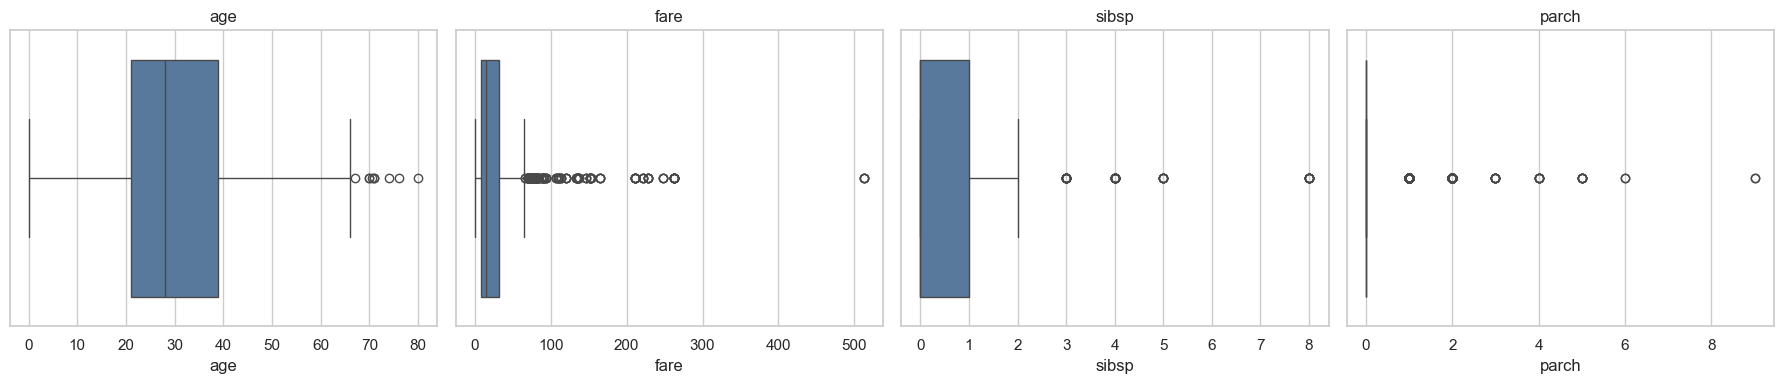

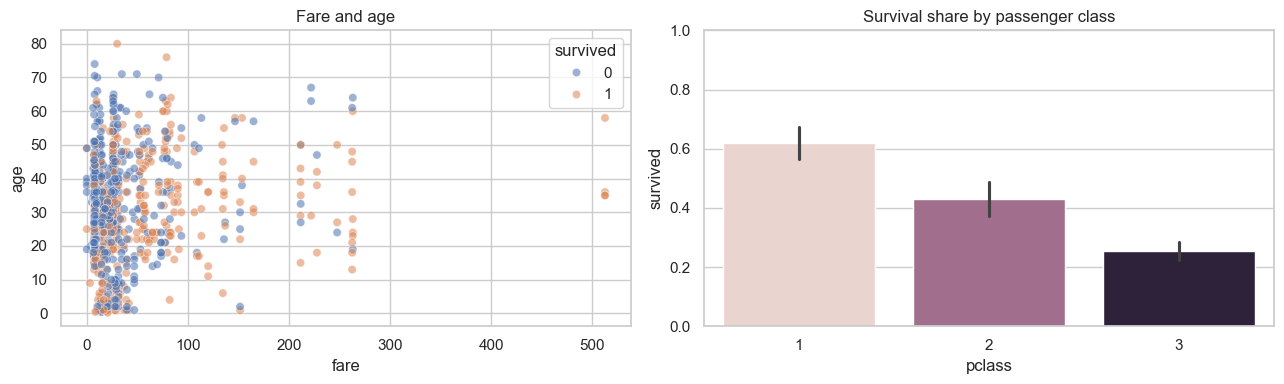

In [3]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,col in zip(axes,numeric_features):
    sns.boxplot(x=data[col],ax=ax,color="#4C78A8"); ax.set_title(col)
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.scatterplot(data=data,x="fare",y="age",hue="survived",alpha=.55,ax=axes[0]); axes[0].set_title("Fare and age")
sns.barplot(data=data,x="pclass",y="survived",hue="pclass",legend=False,ax=axes[1]); axes[1].set_title("Survival share by passenger class"); axes[1].set_ylim(0,1)
plt.tight_layout(); plt.show()

## 3. Split, impute, and define domain limits

The following limits are explicit examples: age is restricted to 0–70, fare to 0–200, siblings/spouses to at most 5, and parents/children to at most 6. These boundaries are not discovered by the transformer. In a real project, verify them with the data dictionary and domain experts.

In [4]:
X=data[numeric_features].copy(); y=data["survived"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.30,random_state=0,stratify=y)
imputer=SimpleImputer(strategy="median")
X_train=pd.DataFrame(imputer.fit_transform(X_train),columns=numeric_features,index=X_train.index)
X_test=pd.DataFrame(imputer.transform(X_test),columns=numeric_features,index=X_test.index)
min_limits={"age":0,"fare":0,"sibsp":0,"parch":0}
max_limits={"age":70,"fare":200,"sibsp":5,"parch":6}
capper=ArbitraryOutlierCapper(max_capping_dict=max_limits,min_capping_dict=min_limits)
capper.fit(X_train)
train_capped=capper.transform(X_train); test_capped=capper.transform(X_test)
display(pd.DataFrame({"minimum cap":pd.Series(capper.left_tail_caps_),"maximum cap":pd.Series(capper.right_tail_caps_)}))

,minimum cap,maximum cap
age,0,70
fare,0,200
sibsp,0,5
parch,0,6


## 4. Audit changed values

Capping keeps the same number of passengers. A changed-row count and before/after boxplots make the transformation reviewable.

,changed_rows
age,4
fare,30
sibsp,5
parch,1


,raw_min,capped_min,raw_max,capped_max
age,0.3333,0.3333,80.0000,70.0
fare,0.0000,0.0000,512.3292,200.0
sibsp,0.0000,0.0000,8.0000,5.0
parch,0.0000,0.0000,9.0000,6.0


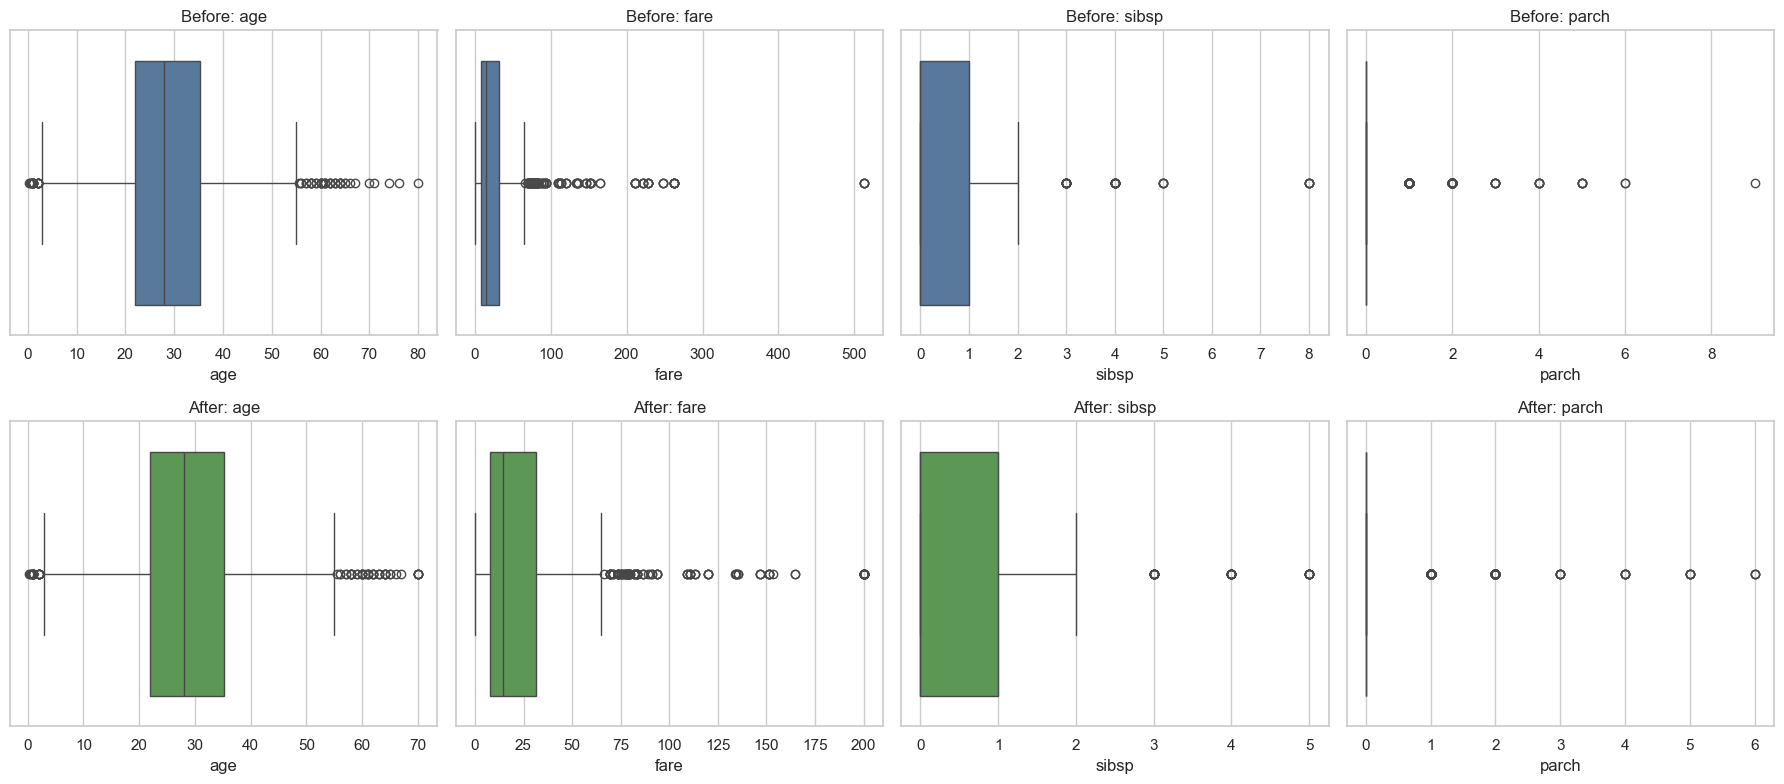

In [5]:
changed=(X_train[numeric_features]!=train_capped[numeric_features]).sum().rename("changed_rows").to_frame()
display(changed)
display(pd.DataFrame({"raw_min":X_train.min(),"capped_min":train_capped.min(),"raw_max":X_train.max(),"capped_max":train_capped.max()}))
fig,axes=plt.subplots(2,4,figsize=(18,8))
for i,col in enumerate(numeric_features):
    sns.boxplot(x=X_train[col],ax=axes[0,i],color="#4C78A8"); axes[0,i].set_title(f"Before: {col}")
    sns.boxplot(x=train_capped[col],ax=axes[1,i],color="#54A24B"); axes[1,i].set_title(f"After: {col}")
plt.tight_layout(); plt.show()

In [6]:
affected=X_train.loc[(X_train[numeric_features]!=train_capped[numeric_features]).any(axis=1),numeric_features].copy()
affected["changed_columns"]=(X_train[numeric_features]!=train_capped[numeric_features]).loc[affected.index].sum(axis=1)
display(affected.head(12))
print("Affected training passengers:",len(affected),f"({len(affected)/len(X_train):.1%})")

,age,fare,sibsp,parch,changed_columns
10,47.0,227.5250,1.0,0.0,1
114,19.0,263.0000,3.0,2.0,1
302,35.0,512.3292,0.0,0.0,1
286,63.0,221.7792,1.0,0.0,1
1176,28.0,69.5500,8.0,2.0,1
1180,28.0,69.5500,1.0,9.0,1
50,58.0,512.3292,0.0,1.0,1
173,32.5,211.5000,0.0,0.0,1
35,45.0,262.3750,0.0,0.0,1
253,48.0,262.3750,1.0,3.0,1


Affected training passengers: 40 (4.4%)


## 5. Check whether capping changes descriptive summaries

The outcome is not used by the capper, but comparing survival shares across fare groups helps show how a transformation may affect downstream interpretation. The comparison is descriptive, not causal.

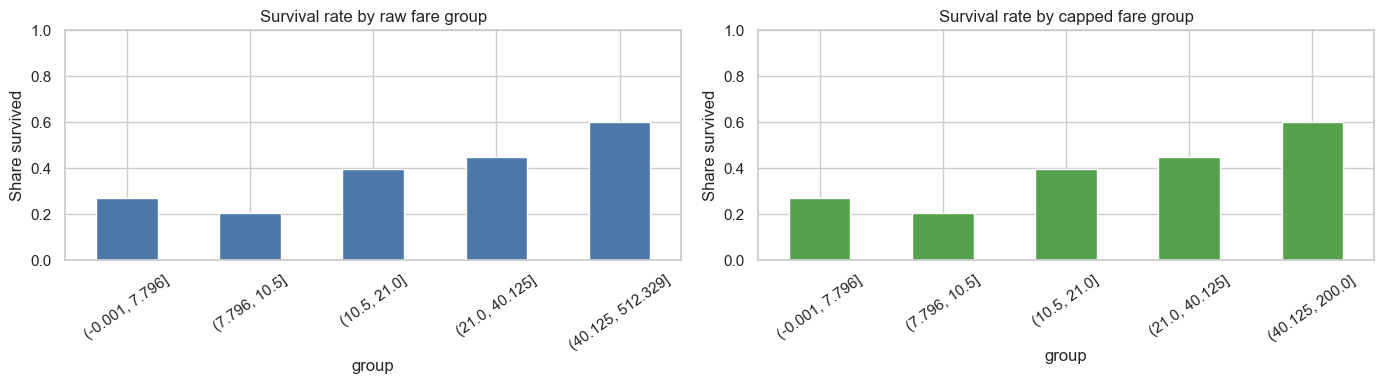

In [7]:
raw_plot=pd.DataFrame({"fare":X_train["fare"],"survived":y_train})
cap_plot=pd.DataFrame({"fare":train_capped["fare"],"survived":y_train})
raw_plot["group"]=pd.qcut(raw_plot["fare"],5,duplicates="drop")
cap_plot["group"]=pd.qcut(cap_plot["fare"],5,duplicates="drop")
fig,axes=plt.subplots(1,2,figsize=(14,4))
raw_plot.groupby("group",observed=True).survived.mean().plot(kind="bar",ax=axes[0],color="#4C78A8",title="Survival rate by raw fare group")
cap_plot.groupby("group",observed=True).survived.mean().plot(kind="bar",ax=axes[1],color="#54A24B",title="Survival rate by capped fare group")
for ax in axes: ax.set_ylim(0,1); ax.set_ylabel("Share survived"); ax.tick_params(axis="x",rotation=35)
plt.tight_layout(); plt.show()

## Summary and cautions

`ArbitraryOutlierCapper` is transparent because every boundary is supplied by the user. It is appropriate for documented domain or data-quality rules, not for silently forcing observations into convenient ranges. Keep the target separate, fit imputation and capping on training data only, inspect affected passengers, and compare against statistical capping and trimming.